<a href="https://colab.research.google.com/github/kris00563-bit/FREE-BOT/blob/main/01_probability_neural_networks_plain_english.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week 1.1: Probability & Neural Networks for Digital Twins
### Plain-English edition — no coding required

## How this notebook works
Every grey box below is a **step you run**, not code you read.

1. Some steps have **boxes to fill in** (type a word, drag a slider, pick from a menu).
2. Press the **▶ play button** on the left of the step.
3. Read the answer that appears underneath.

That's it. The computer writes and runs the code for you.

**Curious what it wrote?** Click **Show code** on any step to read it, then click
**Hide code** in the same place to tuck it away again.

> **Red text means something needs fixing** — read it and press play again.
> **Green means you got it right.** No red at all? You're good.

> **Tip:** run the steps in order the first time. If a step ever complains, just run it again.

**Begin at Step 1.** It asks you to name the five activities your twin will track,
and every step after that uses your words.

## What you will learn
- How AI makes predictions using **probability**
- The basics of **neural networks**
- How both ideas build a **digital twin**

## Digital Twin Context
A **digital twin** is a virtual copy of a person or thing. The one we build can predict
behaviour and preferences, respond to language, and learn from what it sees.

## Key Insight
> "AI isn't thinking; it's predicting the next number."

```markdown
# 🐍 Under the Hood: How the Python Code Works

Let's demystify the "hidden" code in this lesson. Underneath the interactive sliders and text boxes, the computer is running standard, everyday Python. Here is a breakdown of the two most important steps:

### 1. Defining and Storing Your Activities (Step 1)
When you type your five activities, Python stores them in a **list** and creates a **dictionary lookup** to map words to numbers:

```python
# 1. Store your custom activity names in a list
NAMES = ["Sleep", "Brush", "Eat", "Wash", "Leisure"]

# 2. Create a lookup dictionary mapping lowercase words to numbers (index positions)
# This helps the computer understand if "sleep", "Sleep", or "1" all mean the same thing
LOOK = {name.lower(): index for index, name in enumerate(NAMES)}
# Result of LOOK: {'sleep': 0, 'brush': 1, 'eat': 2, 'wash': 3, 'leisure': 4}
```

### 2. Counting Habits & Calculating Probabilities (Step 2)
When you run Step 2, Python counts how often you did each activity using a helper tool from Python's standard library called `Counter`:

```python
from collections import Counter

# Let's say you recorded these 7 days (as index numbers):
days = [0, 1, 2, 1, 3, 1, 4]  # Sleep, Brush, Eat, Brush, Wash, Brush, Leisure

# Count occurrences of each number
counts = Counter(days)
# Result: Counter({1: 3, 0: 1, 2: 1, 3: 1, 4: 1}) -> 'Brush' (1) happened 3 times

# Calculate probability (chance of occurring on any day)
total_days = len(days) # 7

probs = {}
for activity_index, count in counts.items():
    probs[activity_index] = count / total_days

# Let's print the probabilities as percentages
for index, probability in probs.items():
    activity_name = NAMES[index]
    print(f"{activity_name}: {probability:.1%}")
```

* **`Counter`**: An efficient Python dictionary subclass designed specifically for counting items.
* **`count / total_days`**: The mathematical definition of probability—taking the number of times an event occurred divided by the total opportunities.
```

---
## Part 1: Probability Foundations

How does AI make a prediction? It counts what happened before, and works out what is
most likely to happen next. Let's watch that happen with a week of daily activities.

In [1]:
#@title ▶ Step 1 — Name the five activities in your life { display-mode: "form" }
#@markdown Your digital twin needs **five activities** to watch for.
#@markdown We filled in two to start you off — **you choose the other three.**
#@markdown Think about how you really spend a day: Work? Study? Farming? Prayer? Football? Cooking? Commuting?
activity_1 = "Sleep" #@param {type:"string"}
activity_2 = "Brush " #@param {type:"string"}
activity_3 = "Eat" #@param {type:"string"}
activity_4 = "Wash" #@param {type:"string"}
activity_5 = "Leisure" #@param {type:"string"}

# ---- hidden helper code: learners never need to read this ----
import numpy as np, matplotlib.pyplot as plt
from collections import Counter
DEFAULTS = ["Sleep", "Work", "Exercise", "Social", "Leisure"]
NAMES = list(globals().get("_MY_ACTIVITIES") or DEFAULTS)
CUSTOM = bool(globals().get("_MY_ACTIVITIES"))
LOOK = {n.lower(): i for i, n in enumerate(NAMES)}
import sys
from IPython.display import display, HTML
def _msg(text, colour, weight):
    sys.stdout.flush()
    body = text.replace("&", "&amp;").replace("<", "&lt;").replace(">", "&gt;")
    display(HTML('<pre style="margin:0 0 2px 0;font-family:monospace;white-space:pre-wrap;'
                 'font-size:13px;color:' + colour + ';font-weight:' + weight + '">' + body + '</pre>'))
def problem(text): _msg(text, "#C8283C", "700")
def success(text): _msg(text, "#1a7f37", "700")
def note(text):    _msg(text, "#5f6368", "400")
def parse_days(text):
    out, bad = [], []
    for w in text.replace(chr(10), ",").split(","):
        w = w.strip()
        if not w: continue
        if w.lower() in LOOK: out.append(LOOK[w.lower()])
        elif w.isdigit() and 1 <= int(w) <= len(NAMES): out.append(int(w) - 1)
        else: bad.append(w)
    return out, bad
def say_bad(bad):
    if not bad: return
    import difflib
    problem("These are not among your five activities: " + ", ".join(bad))
    for w in bad[:3]:
        close = difflib.get_close_matches(w.lower(), [n.lower() for n in NAMES], n=1, cutoff=0.6)
        if close:
            note("   Did you mean " + NAMES[[n.lower() for n in NAMES].index(close[0])] + " instead of " + w + "?")
    note("Your five activities are: " + ", ".join(NAMES))
    note("Rewrite your days using those words, then press play again.")
    if not CUSTOM:
        note("(Tip: run Step 1 to choose your own activity names.)")
    print("")
SAMPLE = [0, 1, 2, 1, 3, 1, 4, 0, 1, 2, 1, 3, 1, 4, 0]
SAMPLE_LONG = SAMPLE + [1, 1, 2, 3, 4, 0]
def show_menu():
    note("Your five activities: " + ", ".join(str(i + 1) + "=" + n for i, n in enumerate(NAMES)))
    print("")
def show_days(days, heading):
    import textwrap
    words = ", ".join(NAMES[d] for d in days)
    nums = ", ".join(str(d + 1) for d in days)
    print(heading + "  (" + str(len(days)) + " days)")
    for line in textwrap.wrap(words, 70):
        print("   " + line)
    print("   as numbers:  " + nums)
    print("")
def get_days(use_sample, typed, sample=None, what="fortnight"):
    show_menu()
    typed = (typed or "").strip()
    if typed:
        if use_sample:
            note("You typed your own days, so I am using those instead of the sample.")
            print("")
        days, bad = parse_days(typed)
        say_bad(bad)
        if days: show_days(days, "Here is what I read from your box:")
        return days
    if use_sample:
        note("Using a sample " + what + " written in your activities.")
        note("Untick the box above and type your own days to make this about YOU.")
        print("")
        days = list(SAMPLE if sample is None else sample)
        show_days(days, "This is the sample data I am using:")
        return days
    problem("Nothing to work with yet.")
    note("Either tick the sample box above, or type some days, like: " + ", ".join(NAMES[:3]))
    return []
def busiest(days):
    return Counter(days).most_common(1)[0][0] if days else 0
def pick(word):
    w = word.strip().lower()
    if w in LOOK: return LOOK[w]
    if w.isdigit() and 1 <= int(w) <= len(NAMES): return int(w) - 1
    problem("I do not know the activity: " + word)
    note("Your five are: " + ", ".join(NAMES))
    return None

clean = [a.strip() for a in [activity_1, activity_2, activity_3, activity_4, activity_5]]
empty = [i + 1 for i, c in enumerate(clean) if not c]
dupes = [n for n, k in Counter([c.lower() for c in clean if c]).items() if k > 1]
toolong = [c for c in clean if len(c) > 20]
if empty:
    boxes = ", ".join("activity_" + str(i) for i in empty)
    problem("Not finished yet - these boxes are still empty: " + boxes)
    note("")
    note("Type ONE activity in each empty box, then press play again.")
    note("Ideas: Work, Study, Exercise, Social, Family, Farming, Cooking,")
    note("       Commute, Prayer, Football, Music, Chores, Reading")
elif dupes:
    problem("You used the same activity twice: " + ", ".join(dupes))
    note("")
    note("All five need to be different. Change one and press play again.")
elif toolong:
    problem("Keep each activity to one or two words: " + ", ".join(toolong))
else:
    globals()["_MY_ACTIVITIES"] = clean
    success("All five activities set. Nothing in red means you got it right!")
    print("")
    print("Your digital twin will track these five activities:")
    print("")
    for i, c in enumerate(clean, 1):
        print("   " + str(i) + ". " + c)
    print("")
    print("Every step from here on uses YOUR words, not ours.")
    print("")
    print("Here is a sample fortnight written in your activities.")
    print("Copy the line below into Step 2, then edit it to match your real days:")
    print("")
    order = [0, 1, 2, 1, 3, 1, 4, 0, 1, 2, 1, 3, 1, 4, 0]
    print("   " + ", ".join(clean[i] for i in order))


Your digital twin will track these five activities:

   1. Sleep
   2. Brush
   3. Eat
   4. Wash
   5. Leisure

Every step from here on uses YOUR words, not ours.

Here is a sample fortnight written in your activities.
Copy the line below into Step 2, then edit it to match your real days:

   Sleep, Brush, Eat, Brush, Wash, Brush, Leisure, Sleep, Brush, Eat, Brush, Wash, Brush, Leisure, Sleep


### 1.1 Simple prediction: what do I do most?

The step below counts how often each of **your** activities happens.
Each count becomes a **probability** — the chance of that activity on any random day.

Press play straight away to see it work on a sample week. Then untick the box,
type your own days, and watch the answer change.


Here is what I read from your box:  (18 days)
   Sleep, Brush, Eat, Brush, Wash, Brush, Leisure, Sleep, Brush, Eat,
   Brush, Wash, Brush, Leisure, Sleep, Brush, Brush, Leisure
   as numbers:  1, 2, 3, 2, 4, 2, 5, 1, 2, 3, 2, 4, 2, 5, 1, 2, 2, 5

You gave me 18 days.

Here is how your time splits up:
  Brush        8 of 18    44%  #############
  Sleep        3 of 18    17%  #####
  Leisure      3 of 18    17%  #####
  Eat          2 of 18    11%  ###
  Wash         2 of 18    11%  ###

In plain English: on any random day, the single most likely thing
you are doing is BRUSH (44% of the time).
The rarest is WASH (11%).

So if your twin had to guess RIGHT NOW with no other clues,
it would say: Brush.


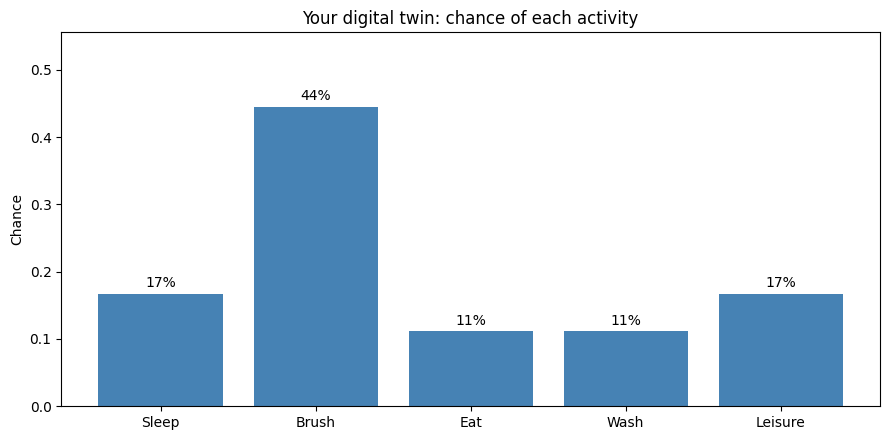

In [4]:
#@title ▶ Step 2 — Count how often I do each activity { display-mode: "form" }
#@markdown **Quickest start:** leave this ticked to use a sample week written in YOUR activities.
use_a_sample_week = False #@param {type:"boolean"}
#@markdown **Or describe your own days** below, separated by commas.
#@markdown Type the words, or just the numbers from Step 1 (1 = your first activity).
my_days = "Sleep, Brush, Eat, Brush, Wash, Brush, Leisure, Sleep, Brush, Eat, Brush, Wash, Brush, Leisure, Sleep, brush, sad, brush, leisure  " #@param {type:"string"}

# ---- hidden helper code: learners never need to read this ----
import numpy as np, matplotlib.pyplot as plt
from collections import Counter
DEFAULTS = ["Sleep", "Work", "Exercise", "Social", "Leisure"]
NAMES = list(globals().get("_MY_ACTIVITIES") or DEFAULTS)
CUSTOM = bool(globals().get("_MY_ACTIVITIES"))
LOOK = {n.lower(): i for i, n in enumerate(NAMES)}
import sys
from IPython.display import display, HTML
def _msg(text, colour, weight):
    sys.stdout.flush()
    body = text.replace("&", "&amp;").replace("<", "&lt;").replace(">", "&gt;")
    display(HTML('<pre style="margin:0 0 2px 0;font-family:monospace;white-space:pre-wrap;'
                 'font-size:13px;color:' + colour + ';font-weight:' + weight + '">' + body + '</pre>'))
def problem(text): _msg(text, "#C8283C", "700")
def success(text): _msg(text, "#1a7f37", "700")
def note(text):    _msg(text, "#5f6368", "400")
def parse_days(text):
    out, bad = [], []
    for w in text.replace(chr(10), ",").split(","):
        w = w.strip()
        if not w: continue
        if w.lower() in LOOK: out.append(LOOK[w.lower()])
        elif w.isdigit() and 1 <= int(w) <= len(NAMES): out.append(int(w) - 1)
        else: bad.append(w)
    return out, bad
def say_bad(bad):
    if not bad: return
    import difflib
    problem("These are not among your five activities: " + ", ".join(bad))
    for w in bad[:3]:
        close = difflib.get_close_matches(w.lower(), [n.lower() for n in NAMES], n=1, cutoff=0.6)
        if close:
            note("   Did you mean " + NAMES[[n.lower() for n in NAMES].index(close[0])] + " instead of " + w + "?")
    note("Your five activities are: " + ", ".join(NAMES))
    note("Rewrite your days using those words, then press play again.")
    if not CUSTOM:
        note("(Tip: run Step 1 to choose your own activity names.)")
    print("")
SAMPLE = [0, 1, 2, 1, 3, 1, 4, 0, 1, 2, 1, 3, 1, 4, 0]
SAMPLE_LONG = SAMPLE + [1, 1, 2, 3, 4, 0]
def show_menu():
    note("Your five activities: " + ", ".join(str(i + 1) + "=" + n for i, n in enumerate(NAMES)))
    print("")
def show_days(days, heading):
    import textwrap
    words = ", ".join(NAMES[d] for d in days)
    nums = ", ".join(str(d + 1) for d in days)
    print(heading + "  (" + str(len(days)) + " days)")
    for line in textwrap.wrap(words, 70):
        print("   " + line)
    print("   as numbers:  " + nums)
    print("")
def get_days(use_sample, typed, sample=None, what="fortnight"):
    show_menu()
    typed = (typed or "").strip()
    if typed:
        if use_sample:
            note("You typed your own days, so I am using those instead of the sample.")
            print("")
        days, bad = parse_days(typed)
        say_bad(bad)
        if days: show_days(days, "Here is what I read from your box:")
        return days
    if use_sample:
        note("Using a sample " + what + " written in your activities.")
        note("Untick the box above and type your own days to make this about YOU.")
        print("")
        days = list(SAMPLE if sample is None else sample)
        show_days(days, "This is the sample data I am using:")
        return days
    problem("Nothing to work with yet.")
    note("Either tick the sample box above, or type some days, like: " + ", ".join(NAMES[:3]))
    return []
def busiest(days):
    return Counter(days).most_common(1)[0][0] if days else 0
def pick(word):
    w = word.strip().lower()
    if w in LOOK: return LOOK[w]
    if w.isdigit() and 1 <= int(w) <= len(NAMES): return int(w) - 1
    problem("I do not know the activity: " + word)
    note("Your five are: " + ", ".join(NAMES))
    return None

days = get_days(use_a_sample_week, my_days)
if len(days) < 2:
    if days: problem("I need at least 2 days to count anything.")
else:
    counts = Counter(days); total = len(days)
    probs = {a: c / total for a, c in counts.items()}
    order = sorted(probs, key=lambda a: -probs[a])
    print("You gave me " + str(total) + " days.")
    print("")
    print("Here is how your time splits up:")
    for a in order:
        print("  " + NAMES[a].ljust(12) + str(counts[a]).rjust(2) + " of " + str(total) + "  " +
              format(probs[a], ">5.0%") + "  " + "#" * int(round(probs[a] * 30)))
    top, bottom = order[0], order[-1]
    print("")
    print("In plain English: on any random day, the single most likely thing")
    print("you are doing is " + NAMES[top].upper() + " (" + format(probs[top], ".0%") + " of the time).")
    print("The rarest is " + NAMES[bottom].upper() + " (" + format(probs[bottom], ".0%") + ").")
    print("")
    print("So if your twin had to guess RIGHT NOW with no other clues,")
    print("it would say: " + NAMES[top] + ".")
    missing = [NAMES[i] for i in range(len(NAMES)) if i not in counts]
    if missing:
        print("")
        note("You never mentioned: " + ", ".join(missing) + ". Your twin will never predict those.")
    if total < 7:
        print("")
        note("That is only " + str(total) + " days. Add more for a steadier picture.")
    plt.figure(figsize=(9, 4.5)); ks = sorted(probs)
    plt.bar([NAMES[k] for k in ks], [probs[k] for k in ks], color="steelblue")
    plt.title("Your digital twin: chance of each activity")
    plt.ylabel("Chance"); plt.ylim(0, max(probs.values()) * 1.25)
    for i, k in enumerate(ks): plt.text(i, probs[k] + 0.01, format(probs[k], ".0%"), ha="center")
    plt.tight_layout(); plt.show()

### 🎯 Exercise 1.1 (Easy): Your own two weeks

**Task:** in the step below, replace the example with **your own 14 days**.
Think about yesterday, the day before, and so on — one word per day.

**Then answer for yourself:**
1. Which activity has the highest chance?
2. What does that say about your routine?
3. What do you think would change if you entered 100 days instead of 14?

In [6]:
#@title ▶ Step 3 — Try it with your own two weeks { display-mode: "form" }
#@markdown This is YOUR turn. Think back over the last fortnight, one word per day.
#@markdown Leave the box empty to borrow a sample fortnight instead.
use_a_sample_week = True #@param {type:"boolean"}
my_two_weeks = "Sleep, Brush, Eat, Brush, Wash, Brush, Leisure, Sleep, Brush, Eat, Brush, Wash, Brush, Leisure" #@param {type:"string"}

# ---- hidden helper code: learners never need to read this ----
import numpy as np, matplotlib.pyplot as plt
from collections import Counter
DEFAULTS = ["Sleep", "Work", "Exercise", "Social", "Leisure"]
NAMES = list(globals().get("_MY_ACTIVITIES") or DEFAULTS)
CUSTOM = bool(globals().get("_MY_ACTIVITIES"))
LOOK = {n.lower(): i for i, n in enumerate(NAMES)}
import sys
from IPython.display import display, HTML
def _msg(text, colour, weight):
    sys.stdout.flush()
    body = text.replace("&", "&amp;").replace("<", "&lt;").replace(">", "&gt;")
    display(HTML('<pre style="margin:0 0 2px 0;font-family:monospace;white-space:pre-wrap;'
                 'font-size:13px;color:' + colour + ';font-weight:' + weight + '">' + body + '</pre>'))
def problem(text): _msg(text, "#C8283C", "700")
def success(text): _msg(text, "#1a7f37", "700")
def note(text):    _msg(text, "#5f6368", "400")
def parse_days(text):
    out, bad = [], []
    for w in text.replace(chr(10), ",").split(","):
        w = w.strip()
        if not w: continue
        if w.lower() in LOOK: out.append(LOOK[w.lower()])
        elif w.isdigit() and 1 <= int(w) <= len(NAMES): out.append(int(w) - 1)
        else: bad.append(w)
    return out, bad
def say_bad(bad):
    if not bad: return
    import difflib
    problem("These are not among your five activities: " + ", ".join(bad))
    for w in bad[:3]:
        close = difflib.get_close_matches(w.lower(), [n.lower() for n in NAMES], n=1, cutoff=0.6)
        if close:
            note("   Did you mean " + NAMES[[n.lower() for n in NAMES].index(close[0])] + " instead of " + w + "?")
    note("Your five activities are: " + ", ".join(NAMES))
    note("Rewrite your days using those words, then press play again.")
    if not CUSTOM:
        note("(Tip: run Step 1 to choose your own activity names.)")
    print("")
SAMPLE = [0, 1, 2, 1, 3, 1, 4, 0, 1, 2, 1, 3, 1, 4, 0]
SAMPLE_LONG = SAMPLE + [1, 1, 2, 3, 4, 0]
def show_menu():
    note("Your five activities: " + ", ".join(str(i + 1) + "=" + n for i, n in enumerate(NAMES)))
    print("")
def show_days(days, heading):
    import textwrap
    words = ", ".join(NAMES[d] for d in days)
    nums = ", ".join(str(d + 1) for d in days)
    print(heading + "  (" + str(len(days)) + " days)")
    for line in textwrap.wrap(words, 70):
        print("   " + line)
    print("   as numbers:  " + nums)
    print("")
def get_days(use_sample, typed, sample=None, what="fortnight"):
    show_menu()
    typed = (typed or "").strip()
    if typed:
        if use_sample:
            note("You typed your own days, so I am using those instead of the sample.")
            print("")
        days, bad = parse_days(typed)
        say_bad(bad)
        if days: show_days(days, "Here is what I read from your box:")
        return days
    if use_sample:
        note("Using a sample " + what + " written in your activities.")
        note("Untick the box above and type your own days to make this about YOU.")
        print("")
        days = list(SAMPLE if sample is None else sample)
        show_days(days, "This is the sample data I am using:")
        return days
    problem("Nothing to work with yet.")
    note("Either tick the sample box above, or type some days, like: " + ", ".join(NAMES[:3]))
    return []
def busiest(days):
    return Counter(days).most_common(1)[0][0] if days else 0
def pick(word):
    w = word.strip().lower()
    if w in LOOK: return LOOK[w]
    if w.isdigit() and 1 <= int(w) <= len(NAMES): return int(w) - 1
    problem("I do not know the activity: " + word)
    note("Your five are: " + ", ".join(NAMES))
    return None

days = get_days(use_a_sample_week, my_two_weeks)
if len(days) >= 2:
    counts = Counter(days); total = len(days)
    probs = {a: c / total for a, c in counts.items()}
    order = sorted(probs, key=lambda a: -probs[a])
    print("Your " + str(total) + " days, most common first:")
    print("")
    for a in order:
        print("  " + NAMES[a].ljust(12) + format(probs[a], ">5.0%") + "  " + "#" * int(round(probs[a] * 40)))
    print("")
    print("1. Highest chance: " + NAMES[order[0]])
    missing = [NAMES[i] for i in range(len(NAMES)) if i not in counts]
    if missing:
        print("2. You never recorded: " + ", ".join(missing) + ".")
        print("   A twin trained on this would predict those NEVER happen.")
        print("   That is the danger of judging someone on too little data.")
    else:
        print("2. Every activity appears at least once, so your twin keeps all five options open.")
    print("3. With 100 days these percentages would settle down and wobble far less.")
    print("")
    print("So what? Your twin is only ever as good as the days you feed it.")
elif days:
    problem("I need at least 2 days.")


Here is what I read from your box:  (14 days)
   Sleep, Brush, Eat, Brush, Wash, Brush, Leisure, Sleep, Brush, Eat,
   Brush, Wash, Brush, Leisure
   as numbers:  1, 2, 3, 2, 4, 2, 5, 1, 2, 3, 2, 4, 2, 5

Your 14 days, most common first:

  Brush         43%  #################
  Sleep         14%  ######
  Eat           14%  ######
  Wash          14%  ######
  Leisure       14%  ######

1. Highest chance: Brush
2. Every activity appears at least once, so your twin keeps all five options open.
3. With 100 days these percentages would settle down and wobble far less.

So what? Your twin is only ever as good as the days you feed it.


### 1.2 Context matters: what usually comes *next*?

Counting alone ignores order. In real life, what you do next depends on what you just did.
The next step learns the rule **"after X, you usually do Y"**.

In [7]:
#@title ▶ Step 4 — Learn what usually follows what { display-mode: "form" }
#@markdown Same days as before. Order matters now, so keep them in the order they happened.
use_a_sample_week = True #@param {type:"boolean"}
my_days = "" #@param {type:"string"}

# ---- hidden helper code: learners never need to read this ----
import numpy as np, matplotlib.pyplot as plt
from collections import Counter
DEFAULTS = ["Sleep", "Work", "Exercise", "Social", "Leisure"]
NAMES = list(globals().get("_MY_ACTIVITIES") or DEFAULTS)
CUSTOM = bool(globals().get("_MY_ACTIVITIES"))
LOOK = {n.lower(): i for i, n in enumerate(NAMES)}
import sys
from IPython.display import display, HTML
def _msg(text, colour, weight):
    sys.stdout.flush()
    body = text.replace("&", "&amp;").replace("<", "&lt;").replace(">", "&gt;")
    display(HTML('<pre style="margin:0 0 2px 0;font-family:monospace;white-space:pre-wrap;'
                 'font-size:13px;color:' + colour + ';font-weight:' + weight + '">' + body + '</pre>'))
def problem(text): _msg(text, "#C8283C", "700")
def success(text): _msg(text, "#1a7f37", "700")
def note(text):    _msg(text, "#5f6368", "400")
def parse_days(text):
    out, bad = [], []
    for w in text.replace(chr(10), ",").split(","):
        w = w.strip()
        if not w: continue
        if w.lower() in LOOK: out.append(LOOK[w.lower()])
        elif w.isdigit() and 1 <= int(w) <= len(NAMES): out.append(int(w) - 1)
        else: bad.append(w)
    return out, bad
def say_bad(bad):
    if not bad: return
    import difflib
    problem("These are not among your five activities: " + ", ".join(bad))
    for w in bad[:3]:
        close = difflib.get_close_matches(w.lower(), [n.lower() for n in NAMES], n=1, cutoff=0.6)
        if close:
            note("   Did you mean " + NAMES[[n.lower() for n in NAMES].index(close[0])] + " instead of " + w + "?")
    note("Your five activities are: " + ", ".join(NAMES))
    note("Rewrite your days using those words, then press play again.")
    if not CUSTOM:
        note("(Tip: run Step 1 to choose your own activity names.)")
    print("")
SAMPLE = [0, 1, 2, 1, 3, 1, 4, 0, 1, 2, 1, 3, 1, 4, 0]
SAMPLE_LONG = SAMPLE + [1, 1, 2, 3, 4, 0]
def show_menu():
    note("Your five activities: " + ", ".join(str(i + 1) + "=" + n for i, n in enumerate(NAMES)))
    print("")
def show_days(days, heading):
    import textwrap
    words = ", ".join(NAMES[d] for d in days)
    nums = ", ".join(str(d + 1) for d in days)
    print(heading + "  (" + str(len(days)) + " days)")
    for line in textwrap.wrap(words, 70):
        print("   " + line)
    print("   as numbers:  " + nums)
    print("")
def get_days(use_sample, typed, sample=None, what="fortnight"):
    show_menu()
    typed = (typed or "").strip()
    if typed:
        if use_sample:
            note("You typed your own days, so I am using those instead of the sample.")
            print("")
        days, bad = parse_days(typed)
        say_bad(bad)
        if days: show_days(days, "Here is what I read from your box:")
        return days
    if use_sample:
        note("Using a sample " + what + " written in your activities.")
        note("Untick the box above and type your own days to make this about YOU.")
        print("")
        days = list(SAMPLE if sample is None else sample)
        show_days(days, "This is the sample data I am using:")
        return days
    problem("Nothing to work with yet.")
    note("Either tick the sample box above, or type some days, like: " + ", ".join(NAMES[:3]))
    return []
def busiest(days):
    return Counter(days).most_common(1)[0][0] if days else 0
def pick(word):
    w = word.strip().lower()
    if w in LOOK: return LOOK[w]
    if w.isdigit() and 1 <= int(w) <= len(NAMES): return int(w) - 1
    problem("I do not know the activity: " + word)
    note("Your five are: " + ", ".join(NAMES))
    return None

days = get_days(use_a_sample_week, my_days)
if len(days) < 3:
    if days: problem("I need at least 3 days to see what follows what.")
else:
    trans = {}
    for a, b in zip(days, days[1:]): trans.setdefault(a, []).append(b)
    print("What your twin learned about your habits:")
    print("")
    sure = []
    for cur in sorted(trans):
        c = Counter(trans[cur]); tot = len(trans[cur])
        parts = sorted(c.items(), key=lambda kv: -kv[1])
        print("  After " + NAMES[cur].upper() + ", you usually do:")
        for nxt, n in parts:
            print("      " + NAMES[nxt].ljust(12) + format(n / tot, ">5.0%"))
        print("      " + ("(always the same - an easy, confident prediction)" if len(parts) == 1
                          else "(several options - the twin is less certain here)"))
        print("")
        sure.append((parts[0][1] / tot, cur, parts[0][0]))
    best = max(sure); worst = min(sure)
    print("This is CONDITIONAL probability: the chance of something,")
    print("GIVEN what just happened. Context changes the answer.")
    print("")
    print("So what? In Step 2 your twin had one guess for every day.")
    print("Now it knows that after " + NAMES[best[1]] + " you almost always do " + NAMES[best[2]] + ",")
    print("while after " + NAMES[worst[1]] + " it is much less sure. That is a smarter twin.")


This is the sample data I am using:  (15 days)
   Sleep, Brush, Eat, Brush, Wash, Brush, Leisure, Sleep, Brush, Eat,
   Brush, Wash, Brush, Leisure, Sleep
   as numbers:  1, 2, 3, 2, 4, 2, 5, 1, 2, 3, 2, 4, 2, 5, 1

What your twin learned about your habits:

  After SLEEP, you usually do:
      Brush        100%
      (always the same - an easy, confident prediction)

  After BRUSH, you usually do:
      Eat           33%
      Wash          33%
      Leisure       33%
      (several options - the twin is less certain here)

  After EAT, you usually do:
      Brush        100%
      (always the same - an easy, confident prediction)

  After WASH, you usually do:
      Brush        100%
      (always the same - an easy, confident prediction)

  After LEISURE, you usually do:
      Sleep        100%
      (always the same - an easy, confident prediction)

This is CONDITIONAL probability: the chance of something,
GIVEN what just happened. Context changes the answer.

So what? In Step 2 y

### 🎯 Exercise 1.2 (Intermediate): Predict a whole day ahead

Now we use those habits to guess forward. Pick where you are starting, and how many
steps ahead to guess. Each guess feeds into the next — this is called a **Markov chain**,
and it is the same trick a language model uses to write a sentence one word at a time.

In [9]:
#@title ▶ Step 5 — Predict what I will do next { display-mode: "form" }
#@markdown Leave the activity blank and your twin starts from whatever you do most.
starting_activity = "" #@param {type:"string"}
steps_ahead = 9 #@param {type:"slider", min:1, max:10, step:1}
use_a_sample_week = True #@param {type:"boolean"}
my_days = "" #@param {type:"string"}

# ---- hidden helper code: learners never need to read this ----
import numpy as np, matplotlib.pyplot as plt
from collections import Counter
DEFAULTS = ["Sleep", "Work", "Exercise", "Social", "Leisure"]
NAMES = list(globals().get("_MY_ACTIVITIES") or DEFAULTS)
CUSTOM = bool(globals().get("_MY_ACTIVITIES"))
LOOK = {n.lower(): i for i, n in enumerate(NAMES)}
import sys
from IPython.display import display, HTML
def _msg(text, colour, weight):
    sys.stdout.flush()
    body = text.replace("&", "&amp;").replace("<", "&lt;").replace(">", "&gt;")
    display(HTML('<pre style="margin:0 0 2px 0;font-family:monospace;white-space:pre-wrap;'
                 'font-size:13px;color:' + colour + ';font-weight:' + weight + '">' + body + '</pre>'))
def problem(text): _msg(text, "#C8283C", "700")
def success(text): _msg(text, "#1a7f37", "700")
def note(text):    _msg(text, "#5f6368", "400")
def parse_days(text):
    out, bad = [], []
    for w in text.replace(chr(10), ",").split(","):
        w = w.strip()
        if not w: continue
        if w.lower() in LOOK: out.append(LOOK[w.lower()])
        elif w.isdigit() and 1 <= int(w) <= len(NAMES): out.append(int(w) - 1)
        else: bad.append(w)
    return out, bad
def say_bad(bad):
    if not bad: return
    import difflib
    problem("These are not among your five activities: " + ", ".join(bad))
    for w in bad[:3]:
        close = difflib.get_close_matches(w.lower(), [n.lower() for n in NAMES], n=1, cutoff=0.6)
        if close:
            note("   Did you mean " + NAMES[[n.lower() for n in NAMES].index(close[0])] + " instead of " + w + "?")
    note("Your five activities are: " + ", ".join(NAMES))
    note("Rewrite your days using those words, then press play again.")
    if not CUSTOM:
        note("(Tip: run Step 1 to choose your own activity names.)")
    print("")
SAMPLE = [0, 1, 2, 1, 3, 1, 4, 0, 1, 2, 1, 3, 1, 4, 0]
SAMPLE_LONG = SAMPLE + [1, 1, 2, 3, 4, 0]
def show_menu():
    note("Your five activities: " + ", ".join(str(i + 1) + "=" + n for i, n in enumerate(NAMES)))
    print("")
def show_days(days, heading):
    import textwrap
    words = ", ".join(NAMES[d] for d in days)
    nums = ", ".join(str(d + 1) for d in days)
    print(heading + "  (" + str(len(days)) + " days)")
    for line in textwrap.wrap(words, 70):
        print("   " + line)
    print("   as numbers:  " + nums)
    print("")
def get_days(use_sample, typed, sample=None, what="fortnight"):
    show_menu()
    typed = (typed or "").strip()
    if typed:
        if use_sample:
            note("You typed your own days, so I am using those instead of the sample.")
            print("")
        days, bad = parse_days(typed)
        say_bad(bad)
        if days: show_days(days, "Here is what I read from your box:")
        return days
    if use_sample:
        note("Using a sample " + what + " written in your activities.")
        note("Untick the box above and type your own days to make this about YOU.")
        print("")
        days = list(SAMPLE if sample is None else sample)
        show_days(days, "This is the sample data I am using:")
        return days
    problem("Nothing to work with yet.")
    note("Either tick the sample box above, or type some days, like: " + ", ".join(NAMES[:3]))
    return []
def busiest(days):
    return Counter(days).most_common(1)[0][0] if days else 0
def pick(word):
    w = word.strip().lower()
    if w in LOOK: return LOOK[w]
    if w.isdigit() and 1 <= int(w) <= len(NAMES): return int(w) - 1
    problem("I do not know the activity: " + word)
    note("Your five are: " + ", ".join(NAMES))
    return None

days = get_days(use_a_sample_week, my_days)
cur = busiest(days) if not starting_activity.strip() else pick(starting_activity)
if len(days) < 3:
    if days: problem("I need at least 3 days.")
elif cur is not None:
    if not starting_activity.strip():
        note("No starting activity given, so I started from your most common one: " + NAMES[cur])
        print("")
    trans = {}
    for a, b in zip(days, days[1:]): trans.setdefault(a, []).append(b)
    print("Starting from " + NAMES[cur].upper() + ", your twin predicts:")
    print("")
    seen, looped = [], False
    for step in range(1, int(steps_ahead) + 1):
        if cur not in trans:
            print("  Step " + str(step) + ": no idea - your days never show what follows " + NAMES[cur] + ".")
            break
        c = Counter(trans[cur]); tot = len(trans[cur])
        nxt, n = max(c.items(), key=lambda kv: kv[1]); conf = n / tot
        word = "confident" if conf > 0.8 else ("fairly sure" if conf > 0.5 else "guessing")
        print("  Step " + str(step) + ": " + NAMES[nxt].ljust(12) + "(" + format(conf, ".0%") + " - " + word + ")")
        if nxt in seen: looped = True
        seen.append(nxt); cur = nxt
    print("")
    if looped:
        print("Notice it fell into a loop. It always picks the single most likely next step,")
        print("so it repeats itself. Real life is messier - and so is real AI, which")
        print("sometimes picks a less likely option on purpose to stay interesting.")
    print("So what? This is exactly how a chatbot writes a sentence:")
    print("one most-likely step at a time, each one feeding the next.")


This is the sample data I am using:  (15 days)
   Sleep, Brush, Eat, Brush, Wash, Brush, Leisure, Sleep, Brush, Eat,
   Brush, Wash, Brush, Leisure, Sleep
   as numbers:  1, 2, 3, 2, 4, 2, 5, 1, 2, 3, 2, 4, 2, 5, 1




Starting from BRUSH, your twin predicts:

  Step 1: Eat         (33% - guessing)
  Step 2: Brush       (100% - confident)
  Step 3: Eat         (33% - guessing)
  Step 4: Brush       (100% - confident)
  Step 5: Eat         (33% - guessing)
  Step 6: Brush       (100% - confident)
  Step 7: Eat         (33% - guessing)
  Step 8: Brush       (100% - confident)
  Step 9: Eat         (33% - guessing)
  Step 10: Brush       (100% - confident)

Notice it fell into a loop. It always picks the single most likely next step,
so it repeats itself. Real life is messier - and so is real AI, which
sometimes picks a less likely option on purpose to stay interesting.
So what? This is exactly how a chatbot writes a sentence:
one most-likely step at a time, each one feeding the next.


---
## Part 2: Neural Networks Basics

Counting works for simple habits. But what if a decision depends on **several things at once** —
how much you slept, how much free time you have, how energetic you feel?

That's the job of a **neuron**: weigh up each piece of evidence, add it all up, and turn the
total into a probability between 0% and 100%.

How your twin weighed up today:

  Sleep        0.5  x importance 0.3  =   0.15
  Free time    0.5  x importance 0.5  =   0.25
  Energy      0.85  x importance 0.7  =   0.59
  Starting point                         -0.50
  ----------------------------------------------
  TOTAL                                0.49

Squashed into a probability: 62%
Verdict: YOU WILL PROBABLY EXERCISE


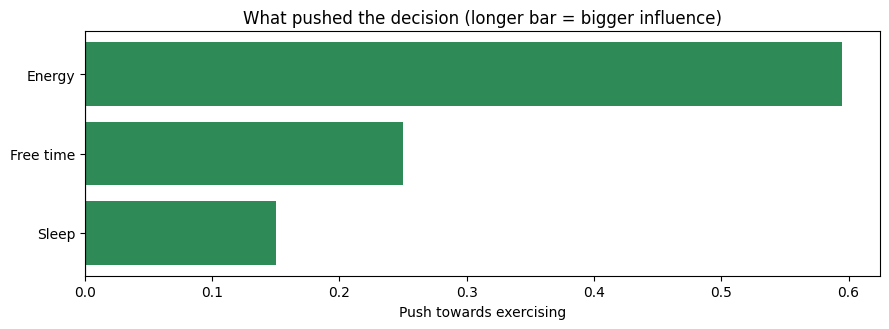

So what? Nobody taught this twin how important sleep or energy are -
we picked those numbers by hand. In Step 8 it works them out for itself.


In [13]:
#@title ▶ Step 6 — Will I exercise today? { display-mode: "form" }
#@markdown Describe today, then press play. The twin weighs it all up and decides.
hours_of_sleep = 0 #@param {type:"slider", min:0, max:12, step:0.5}
free_time_hours = 0.5 #@param {type:"slider", min:0, max:8, step:0.5}
energy_level = 0.85 #@param {type:"slider", min:0, max:1, step:0.05}

# ---- hidden helper code: learners never need to read this ----
import numpy as np, matplotlib.pyplot as plt
from collections import Counter
DEFAULTS = ["Sleep", "Work", "Exercise", "Social", "Leisure"]
NAMES = list(globals().get("_MY_ACTIVITIES") or DEFAULTS)
CUSTOM = bool(globals().get("_MY_ACTIVITIES"))
LOOK = {n.lower(): i for i, n in enumerate(NAMES)}
import sys
from IPython.display import display, HTML
def _msg(text, colour, weight):
    sys.stdout.flush()
    body = text.replace("&", "&amp;").replace("<", "&lt;").replace(">", "&gt;")
    display(HTML('<pre style="margin:0 0 2px 0;font-family:monospace;white-space:pre-wrap;'
                 'font-size:13px;color:' + colour + ';font-weight:' + weight + '">' + body + '</pre>'))
def problem(text): _msg(text, "#C8283C", "700")
def success(text): _msg(text, "#1a7f37", "700")
def note(text):    _msg(text, "#5f6368", "400")
def parse_days(text):
    out, bad = [], []
    for w in text.replace(chr(10), ",").split(","):
        w = w.strip()
        if not w: continue
        if w.lower() in LOOK: out.append(LOOK[w.lower()])
        elif w.isdigit() and 1 <= int(w) <= len(NAMES): out.append(int(w) - 1)
        else: bad.append(w)
    return out, bad
def say_bad(bad):
    if not bad: return
    import difflib
    problem("These are not among your five activities: " + ", ".join(bad))
    for w in bad[:3]:
        close = difflib.get_close_matches(w.lower(), [n.lower() for n in NAMES], n=1, cutoff=0.6)
        if close:
            note("   Did you mean " + NAMES[[n.lower() for n in NAMES].index(close[0])] + " instead of " + w + "?")
    note("Your five activities are: " + ", ".join(NAMES))
    note("Rewrite your days using those words, then press play again.")
    if not CUSTOM:
        note("(Tip: run Step 1 to choose your own activity names.)")
    print("")
SAMPLE = [0, 1, 2, 1, 3, 1, 4, 0, 1, 2, 1, 3, 1, 4, 0]
SAMPLE_LONG = SAMPLE + [1, 1, 2, 3, 4, 0]
def show_menu():
    note("Your five activities: " + ", ".join(str(i + 1) + "=" + n for i, n in enumerate(NAMES)))
    print("")
def show_days(days, heading):
    import textwrap
    words = ", ".join(NAMES[d] for d in days)
    nums = ", ".join(str(d + 1) for d in days)
    print(heading + "  (" + str(len(days)) + " days)")
    for line in textwrap.wrap(words, 70):
        print("   " + line)
    print("   as numbers:  " + nums)
    print("")
def get_days(use_sample, typed, sample=None, what="fortnight"):
    show_menu()
    typed = (typed or "").strip()
    if typed:
        if use_sample:
            note("You typed your own days, so I am using those instead of the sample.")
            print("")
        days, bad = parse_days(typed)
        say_bad(bad)
        if days: show_days(days, "Here is what I read from your box:")
        return days
    if use_sample:
        note("Using a sample " + what + " written in your activities.")
        note("Untick the box above and type your own days to make this about YOU.")
        print("")
        days = list(SAMPLE if sample is None else sample)
        show_days(days, "This is the sample data I am using:")
        return days
    problem("Nothing to work with yet.")
    note("Either tick the sample box above, or type some days, like: " + ", ".join(NAMES[:3]))
    return []
def busiest(days):
    return Counter(days).most_common(1)[0][0] if days else 0
def pick(word):
    w = word.strip().lower()
    if w in LOOK: return LOOK[w]
    if w.isdigit() and 1 <= int(w) <= len(NAMES): return int(w) - 1
    problem("I do not know the activity: " + word)
    note("Your five are: " + ", ".join(NAMES))
    return None

w = np.array([0.3, 0.5, 0.7]); bias = -0.5
x = np.array([hours_of_sleep, free_time_hours, energy_level])
contrib = x * w
total = contrib.sum() + bias
p = 1 / (1 + np.exp(-total))
labels = ["Sleep", "Free time", "Energy"]
print("How your twin weighed up today:\n")
for lab, val, wt, c in zip(labels, x, w, contrib):
    print("  " + lab.ljust(11) + str(val).rjust(5) + "  x importance " + str(wt) + "  = " + format(c, ">6.2f"))
print("  " + "Starting point".ljust(11) + " " * 24 + format(bias, ">6.2f"))
print("  " + "-" * 46)
print("  " + "TOTAL".ljust(11) + " " * 24 + format(total, ">6.2f"))
print("\nSquashed into a probability: " + format(p, ".0%"))
print("Verdict: " + ("YOU WILL PROBABLY EXERCISE" if p > 0.5 else "YOU PROBABLY WILL NOT EXERCISE"))
plt.figure(figsize=(9, 3.4))
cols = ["seagreen" if c >= 0 else "indianred" for c in contrib]
plt.barh(labels, contrib, color=cols)
plt.axvline(0, color="black", linewidth=0.8)
plt.title("What pushed the decision (longer bar = bigger influence)")
plt.xlabel("Push towards exercising")
plt.tight_layout(); plt.show()
print("So what? Nobody taught this twin how important sleep or energy are -")
print("we picked those numbers by hand. In Step 8 it works them out for itself.")

### 🎯 Exercise 2.1 (Easy): Which ingredient matters most?

Go back to Step 6 and try these, one at a time:
1. Drop **sleep** to 4 hours. Does the answer change?
2. Raise **free time** to 4 hours.
3. Drop **energy** to 0.3.

Then run the step below. It tests every possibility for you and shows which
ingredient has the biggest effect on the decision.

Today as you described it: 96% chance of exercising.



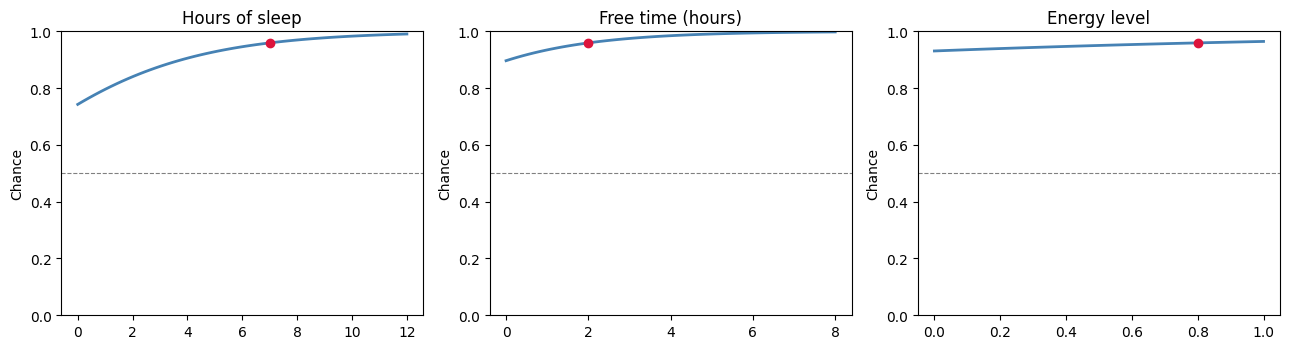

Biggest swing comes from: HOURS OF SLEEP
  Hours of sleep      can change the answer by 25%
  Free time (hours)   can change the answer by 10%
  Energy level        can change the answer by 3%

The red dot is your day. Where the line crosses the dashed grey line,
the twin flips its mind from 'no' to 'yes'.

So what? A twin is only as good as the evidence you feed it -
and some evidence counts far more than the rest.


In [14]:
#@title ▶ Step 7 — Show me which ingredient matters most { display-mode: "form" }
#@markdown Start from the same day you described above.
hours_of_sleep = 7 #@param {type:"slider", min:0, max:12, step:0.5}
free_time_hours = 2 #@param {type:"slider", min:0, max:8, step:0.5}
energy_level = 0.8 #@param {type:"slider", min:0, max:1, step:0.05}

# ---- hidden helper code: learners never need to read this ----
import numpy as np, matplotlib.pyplot as plt
from collections import Counter
DEFAULTS = ["Sleep", "Work", "Exercise", "Social", "Leisure"]
NAMES = list(globals().get("_MY_ACTIVITIES") or DEFAULTS)
CUSTOM = bool(globals().get("_MY_ACTIVITIES"))
LOOK = {n.lower(): i for i, n in enumerate(NAMES)}
import sys
from IPython.display import display, HTML
def _msg(text, colour, weight):
    sys.stdout.flush()
    body = text.replace("&", "&amp;").replace("<", "&lt;").replace(">", "&gt;")
    display(HTML('<pre style="margin:0 0 2px 0;font-family:monospace;white-space:pre-wrap;'
                 'font-size:13px;color:' + colour + ';font-weight:' + weight + '">' + body + '</pre>'))
def problem(text): _msg(text, "#C8283C", "700")
def success(text): _msg(text, "#1a7f37", "700")
def note(text):    _msg(text, "#5f6368", "400")
def parse_days(text):
    out, bad = [], []
    for w in text.replace(chr(10), ",").split(","):
        w = w.strip()
        if not w: continue
        if w.lower() in LOOK: out.append(LOOK[w.lower()])
        elif w.isdigit() and 1 <= int(w) <= len(NAMES): out.append(int(w) - 1)
        else: bad.append(w)
    return out, bad
def say_bad(bad):
    if not bad: return
    import difflib
    problem("These are not among your five activities: " + ", ".join(bad))
    for w in bad[:3]:
        close = difflib.get_close_matches(w.lower(), [n.lower() for n in NAMES], n=1, cutoff=0.6)
        if close:
            note("   Did you mean " + NAMES[[n.lower() for n in NAMES].index(close[0])] + " instead of " + w + "?")
    note("Your five activities are: " + ", ".join(NAMES))
    note("Rewrite your days using those words, then press play again.")
    if not CUSTOM:
        note("(Tip: run Step 1 to choose your own activity names.)")
    print("")
SAMPLE = [0, 1, 2, 1, 3, 1, 4, 0, 1, 2, 1, 3, 1, 4, 0]
SAMPLE_LONG = SAMPLE + [1, 1, 2, 3, 4, 0]
def show_menu():
    note("Your five activities: " + ", ".join(str(i + 1) + "=" + n for i, n in enumerate(NAMES)))
    print("")
def show_days(days, heading):
    import textwrap
    words = ", ".join(NAMES[d] for d in days)
    nums = ", ".join(str(d + 1) for d in days)
    print(heading + "  (" + str(len(days)) + " days)")
    for line in textwrap.wrap(words, 70):
        print("   " + line)
    print("   as numbers:  " + nums)
    print("")
def get_days(use_sample, typed, sample=None, what="fortnight"):
    show_menu()
    typed = (typed or "").strip()
    if typed:
        if use_sample:
            note("You typed your own days, so I am using those instead of the sample.")
            print("")
        days, bad = parse_days(typed)
        say_bad(bad)
        if days: show_days(days, "Here is what I read from your box:")
        return days
    if use_sample:
        note("Using a sample " + what + " written in your activities.")
        note("Untick the box above and type your own days to make this about YOU.")
        print("")
        days = list(SAMPLE if sample is None else sample)
        show_days(days, "This is the sample data I am using:")
        return days
    problem("Nothing to work with yet.")
    note("Either tick the sample box above, or type some days, like: " + ", ".join(NAMES[:3]))
    return []
def busiest(days):
    return Counter(days).most_common(1)[0][0] if days else 0
def pick(word):
    w = word.strip().lower()
    if w in LOOK: return LOOK[w]
    if w.isdigit() and 1 <= int(w) <= len(NAMES): return int(w) - 1
    problem("I do not know the activity: " + word)
    note("Your five are: " + ", ".join(NAMES))
    return None

w = np.array([0.3, 0.5, 0.7]); bias = -0.5
base = np.array([hours_of_sleep, free_time_hours, energy_level])
f = lambda v: 1 / (1 + np.exp(-(np.dot(v, w) + bias)))
ranges = [np.linspace(0, 12, 60), np.linspace(0, 8, 60), np.linspace(0, 1, 60)]
labels = ["Hours of sleep", "Free time (hours)", "Energy level"]
print("Today as you described it: " + format(f(base), ".0%") + " chance of exercising.\n")
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
swings = []
for i, (ax, rng, lab) in enumerate(zip(axes, ranges, labels)):
    ys = []
    for v in rng:
        t = base.copy(); t[i] = v; ys.append(f(t))
    swings.append(max(ys) - min(ys))
    ax.plot(rng, ys, color="steelblue", linewidth=2)
    ax.axhline(0.5, color="grey", linestyle="--", linewidth=0.8)
    ax.scatter([base[i]], [f(base)], color="crimson", zorder=5)
    ax.set_title(lab); ax.set_ylim(0, 1); ax.set_ylabel("Chance")
plt.tight_layout(); plt.show()
best = int(np.argmax(swings))
print("Biggest swing comes from: " + labels[best].upper())
for lab, s in sorted(zip(labels, swings), key=lambda kv: -kv[1]):
    print("  " + lab.ljust(20) + "can change the answer by " + format(s, ".0%"))
print("\nThe red dot is your day. Where the line crosses the dashed grey line,")
print("the twin flips its mind from 'no' to 'yes'.")
print("")
print("So what? A twin is only as good as the evidence you feed it -")
print("and some evidence counts far more than the rest.")

### 2.2 Watching a network learn

Everything so far used importance numbers we picked by hand. A real neural network
**works them out for itself** by looking at examples, guessing, measuring how wrong it was,
and nudging the numbers. Repeat thousands of times, and it learns the pattern.

In the next step the twin learns when someone is likely to **socialise**.

This is the kind of example day the twin studied:

        day-of-week  time-of-day  weather  mood   did they socialise?
   1.       0.37         0.95     0.73   0.60       0.05
   2.       0.16         0.16     0.06   0.87       0.05
   3.       0.60         0.71     0.02   0.97       0.18




The twin studied 500 example days, 1000 times over.

  How wrong it was at the start:  0.1308
  How wrong it was at the end:    0.0411
  Improvement:                    69% better

That falling line below is LEARNING. Nobody told it the rule -
it found it by making mistakes and adjusting.


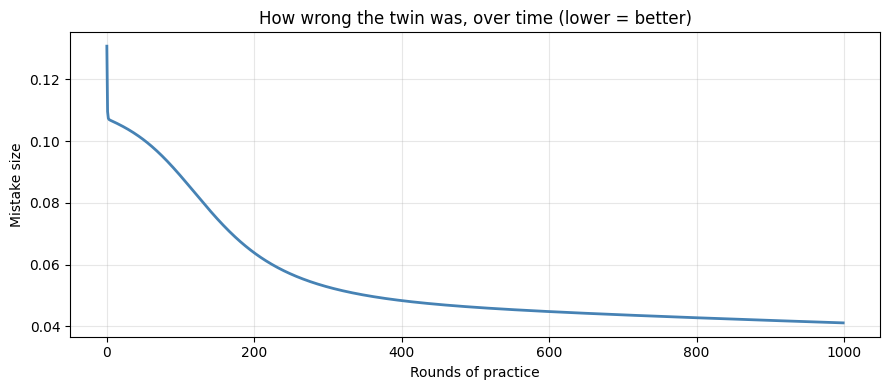


So what? Nobody wrote the rule down. The twin found it by being wrong
thousands of times and adjusting a little after each mistake.


In [16]:
#@title ▶ Step 8 — Train the twin and watch it improve { display-mode: "form" }
#@markdown How much practice should it get? Then press play.
training_examples = 500 #@param {type:"slider", min:50, max:500, step:50}
rounds_of_practice = 1000 #@param {type:"slider", min:100, max:2000, step:100}
learning_speed = 0.85 #@param {type:"slider", min:0.05, max:1, step:0.05}

# ---- hidden helper code: learners never need to read this ----
import numpy as np, matplotlib.pyplot as plt
from collections import Counter
DEFAULTS = ["Sleep", "Work", "Exercise", "Social", "Leisure"]
NAMES = list(globals().get("_MY_ACTIVITIES") or DEFAULTS)
CUSTOM = bool(globals().get("_MY_ACTIVITIES"))
LOOK = {n.lower(): i for i, n in enumerate(NAMES)}
import sys
from IPython.display import display, HTML
def _msg(text, colour, weight):
    sys.stdout.flush()
    body = text.replace("&", "&amp;").replace("<", "&lt;").replace(">", "&gt;")
    display(HTML('<pre style="margin:0 0 2px 0;font-family:monospace;white-space:pre-wrap;'
                 'font-size:13px;color:' + colour + ';font-weight:' + weight + '">' + body + '</pre>'))
def problem(text): _msg(text, "#C8283C", "700")
def success(text): _msg(text, "#1a7f37", "700")
def note(text):    _msg(text, "#5f6368", "400")
def parse_days(text):
    out, bad = [], []
    for w in text.replace(chr(10), ",").split(","):
        w = w.strip()
        if not w: continue
        if w.lower() in LOOK: out.append(LOOK[w.lower()])
        elif w.isdigit() and 1 <= int(w) <= len(NAMES): out.append(int(w) - 1)
        else: bad.append(w)
    return out, bad
def say_bad(bad):
    if not bad: return
    import difflib
    problem("These are not among your five activities: " + ", ".join(bad))
    for w in bad[:3]:
        close = difflib.get_close_matches(w.lower(), [n.lower() for n in NAMES], n=1, cutoff=0.6)
        if close:
            note("   Did you mean " + NAMES[[n.lower() for n in NAMES].index(close[0])] + " instead of " + w + "?")
    note("Your five activities are: " + ", ".join(NAMES))
    note("Rewrite your days using those words, then press play again.")
    if not CUSTOM:
        note("(Tip: run Step 1 to choose your own activity names.)")
    print("")
SAMPLE = [0, 1, 2, 1, 3, 1, 4, 0, 1, 2, 1, 3, 1, 4, 0]
SAMPLE_LONG = SAMPLE + [1, 1, 2, 3, 4, 0]
def show_menu():
    note("Your five activities: " + ", ".join(str(i + 1) + "=" + n for i, n in enumerate(NAMES)))
    print("")
def show_days(days, heading):
    import textwrap
    words = ", ".join(NAMES[d] for d in days)
    nums = ", ".join(str(d + 1) for d in days)
    print(heading + "  (" + str(len(days)) + " days)")
    for line in textwrap.wrap(words, 70):
        print("   " + line)
    print("   as numbers:  " + nums)
    print("")
def get_days(use_sample, typed, sample=None, what="fortnight"):
    show_menu()
    typed = (typed or "").strip()
    if typed:
        if use_sample:
            note("You typed your own days, so I am using those instead of the sample.")
            print("")
        days, bad = parse_days(typed)
        say_bad(bad)
        if days: show_days(days, "Here is what I read from your box:")
        return days
    if use_sample:
        note("Using a sample " + what + " written in your activities.")
        note("Untick the box above and type your own days to make this about YOU.")
        print("")
        days = list(SAMPLE if sample is None else sample)
        show_days(days, "This is the sample data I am using:")
        return days
    problem("Nothing to work with yet.")
    note("Either tick the sample box above, or type some days, like: " + ", ".join(NAMES[:3]))
    return []
def busiest(days):
    return Counter(days).most_common(1)[0][0] if days else 0
def pick(word):
    w = word.strip().lower()
    if w in LOOK: return LOOK[w]
    if w.isdigit() and 1 <= int(w) <= len(NAMES): return int(w) - 1
    problem("I do not know the activity: " + word)
    note("Your five are: " + ", ".join(NAMES))
    return None

rng = np.random.RandomState(42)
n = int(training_examples)
X = rng.rand(n, 4)
y = ((X[:, 0] > 0.7) & (X[:, 2] > 0.5)).astype(float).reshape(-1, 1)
y = np.clip(y + rng.rand(n, 1) * 0.2, 0, 1)
sig = lambda z: 1 / (1 + np.exp(-z))
W1 = rng.randn(4, 8) * 0.5; b1 = np.zeros((1, 8))
W2 = rng.randn(8, 1) * 0.5; b2 = np.zeros((1, 1))
hist = []
for ep in range(int(rounds_of_practice)):
    a1 = sig(X.dot(W1) + b1); out = sig(a1.dot(W2) + b2)
    hist.append(float(np.mean((out - y) ** 2)))
    d2 = out - y
    dW2 = a1.T.dot(d2) / n; db2 = d2.sum(0, keepdims=True) / n
    d1 = d2.dot(W2.T) * a1 * (1 - a1)
    dW1 = X.T.dot(d1) / n; db1 = d1.sum(0, keepdims=True) / n
    W2 -= learning_speed * dW2; b2 -= learning_speed * db2
    W1 -= learning_speed * dW1; b1 -= learning_speed * db1
globals()["_TWIN"] = (W1, b1, W2, b2)
print("This is the kind of example day the twin studied:")
print("")
print("        day-of-week  time-of-day  weather  mood   did they socialise?")
for r in range(3):
    row = X[r]
    print("   " + str(r + 1) + ".   " + format(row[0], ">8.2f") + format(row[1], ">13.2f") +
          format(row[2], ">9.2f") + format(row[3], ">7.2f") + "   " + format(float(y[r][0]), ">8.2f"))
print("")
note("Every number runs from 0 to 1. A 1.00 in the last column means they did socialise.")
print("")
start, end = hist[0], hist[-1]
print("The twin studied " + str(n) + " example days, " + str(int(rounds_of_practice)) + " times over.\n")
print("  How wrong it was at the start:  " + format(start, ".4f"))
print("  How wrong it was at the end:    " + format(end, ".4f"))
print("  Improvement:                    " + format((start - end) / start, ".0%") + " better\n")
if end < start * 0.6:
    print("That falling line below is LEARNING. Nobody told it the rule -")
    print("it found it by making mistakes and adjusting.")
else:
    print("It barely improved. Try more rounds of practice, or a higher learning speed.")
plt.figure(figsize=(9, 4))
plt.plot(hist, color="steelblue", linewidth=2)
plt.title("How wrong the twin was, over time (lower = better)")
plt.xlabel("Rounds of practice"); plt.ylabel("Mistake size")
plt.grid(alpha=0.3); plt.tight_layout(); plt.show()
print("")
print("So what? Nobody wrote the rule down. The twin found it by being wrong")
print("thousands of times and adjusting a little after each mistake.")

### 🎯 Exercise 2.2 (Intermediate): Ask the trained twin about a real day

The twin has learned a pattern. Now question it. Describe a day in the boxes below
and see what it predicts — then check whether its answer seems sensible to you.

In [22]:
#@title ▶ Step 9 — Ask the twin about a specific day { display-mode: "form" }
#@markdown Describe the day, then press play.
day_of_week = "Sunday" #@param ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
time_of_day = 16 #@param {type:"slider", min:0, max:23, step:1}
weather = 0.3 #@param {type:"slider", min:0, max:1, step:0.05}
mood = 0.5 #@param {type:"slider", min:0, max:1, step:0.05}

# ---- hidden helper code: learners never need to read this ----
import numpy as np, matplotlib.pyplot as plt
from collections import Counter
DEFAULTS = ["Sleep", "Work", "Exercise", "Social", "Leisure"]
NAMES = list(globals().get("_MY_ACTIVITIES") or DEFAULTS)
CUSTOM = bool(globals().get("_MY_ACTIVITIES"))
LOOK = {n.lower(): i for i, n in enumerate(NAMES)}
import sys
from IPython.display import display, HTML
def _msg(text, colour, weight):
    sys.stdout.flush()
    body = text.replace("&", "&amp;").replace("<", "&lt;").replace(">", "&gt;")
    display(HTML('<pre style="margin:0 0 2px 0;font-family:monospace;white-space:pre-wrap;'
                 'font-size:13px;color:' + colour + ';font-weight:' + weight + '">' + body + '</pre>'))
def problem(text): _msg(text, "#C8283C", "700")
def success(text): _msg(text, "#1a7f37", "700")
def note(text):    _msg(text, "#5f6368", "400")
def parse_days(text):
    out, bad = [], []
    for w in text.replace(chr(10), ",").split(","):
        w = w.strip()
        if not w: continue
        if w.lower() in LOOK: out.append(LOOK[w.lower()])
        elif w.isdigit() and 1 <= int(w) <= len(NAMES): out.append(int(w) - 1)
        else: bad.append(w)
    return out, bad
def say_bad(bad):
    if not bad: return
    import difflib
    problem("These are not among your five activities: " + ", ".join(bad))
    for w in bad[:3]:
        close = difflib.get_close_matches(w.lower(), [n.lower() for n in NAMES], n=1, cutoff=0.6)
        if close:
            note("   Did you mean " + NAMES[[n.lower() for n in NAMES].index(close[0])] + " instead of " + w + "?")
    note("Your five activities are: " + ", ".join(NAMES))
    note("Rewrite your days using those words, then press play again.")
    if not CUSTOM:
        note("(Tip: run Step 1 to choose your own activity names.)")
    print("")
SAMPLE = [0, 1, 2, 1, 3, 1, 4, 0, 1, 2, 1, 3, 1, 4, 0]
SAMPLE_LONG = SAMPLE + [1, 1, 2, 3, 4, 0]
def show_menu():
    note("Your five activities: " + ", ".join(str(i + 1) + "=" + n for i, n in enumerate(NAMES)))
    print("")
def show_days(days, heading):
    import textwrap
    words = ", ".join(NAMES[d] for d in days)
    nums = ", ".join(str(d + 1) for d in days)
    print(heading + "  (" + str(len(days)) + " days)")
    for line in textwrap.wrap(words, 70):
        print("   " + line)
    print("   as numbers:  " + nums)
    print("")
def get_days(use_sample, typed, sample=None, what="fortnight"):
    show_menu()
    typed = (typed or "").strip()
    if typed:
        if use_sample:
            note("You typed your own days, so I am using those instead of the sample.")
            print("")
        days, bad = parse_days(typed)
        say_bad(bad)
        if days: show_days(days, "Here is what I read from your box:")
        return days
    if use_sample:
        note("Using a sample " + what + " written in your activities.")
        note("Untick the box above and type your own days to make this about YOU.")
        print("")
        days = list(SAMPLE if sample is None else sample)
        show_days(days, "This is the sample data I am using:")
        return days
    problem("Nothing to work with yet.")
    note("Either tick the sample box above, or type some days, like: " + ", ".join(NAMES[:3]))
    return []
def busiest(days):
    return Counter(days).most_common(1)[0][0] if days else 0
def pick(word):
    w = word.strip().lower()
    if w in LOOK: return LOOK[w]
    if w.isdigit() and 1 <= int(w) <= len(NAMES): return int(w) - 1
    problem("I do not know the activity: " + word)
    note("Your five are: " + ", ".join(NAMES))
    return None

if "_TWIN" not in globals():
    print("(Training the twin first - run Step 8 yourself to watch this happen.)\n")
    rng = np.random.RandomState(42)
    X = rng.rand(100, 4)
    y = np.clip(((X[:, 0] > 0.7) & (X[:, 2] > 0.5)).astype(float).reshape(-1, 1) + rng.rand(100, 1) * 0.2, 0, 1)
    sig = lambda z: 1 / (1 + np.exp(-z))
    W1 = rng.randn(4, 8) * 0.5; b1 = np.zeros((1, 8))
    W2 = rng.randn(8, 1) * 0.5; b2 = np.zeros((1, 1))
    for _ in range(500):
        a1 = sig(X.dot(W1) + b1); out = sig(a1.dot(W2) + b2)
        d2 = out - y
        dW2 = a1.T.dot(d2) / 100; db2 = d2.sum(0, keepdims=True) / 100
        d1 = d2.dot(W2.T) * a1 * (1 - a1)
        dW1 = X.T.dot(d1) / 100; db1 = d1.sum(0, keepdims=True) / 100
        W2 -= 0.5 * dW2; b2 -= 0.5 * db2; W1 -= 0.5 * dW1; b1 -= 0.5 * db1
    globals()["_TWIN"] = (W1, b1, W2, b2)
W1, b1, W2, b2 = globals()["_TWIN"]
sig = lambda z: 1 / (1 + np.exp(-z))
DAYS = ["Monday","Tuesday","Wednesday","Thursday","Friday","Saturday","Sunday"]
d = DAYS.index(day_of_week)
x = np.array([[d / 6, time_of_day / 23, weather, mood]])
p = float(sig(sig(x.dot(W1) + b1).dot(W2) + b2)[0][0])
desc = "lovely" if weather > 0.66 else ("okay" if weather > 0.33 else "miserable")
feel = "great" if mood > 0.66 else ("so-so" if mood > 0.33 else "low")
print("You described: " + day_of_week + " at " + str(time_of_day) + ":00, " + desc + " weather, feeling " + feel + ".\n")
print("  Chance of socialising: " + format(p, ".0%"))
print("  The twin says: " + ("LIKELY to socialise" if p > 0.5 else "UNLIKELY to socialise") + "\n")
print("Now compare a few days side by side:")
for lab, dd, tt, ww, mm in [("Weekend evening, good weather", 5, 18, 0.8, 0.9),
                             ("Weekday morning, poor weather", 1, 8, 0.3, 0.5),
                             ("Weekend afternoon, bad weather", 5, 14, 0.2, 0.6)]:
    xx = np.array([[dd / 6, tt / 23, ww, mm]])
    pp = float(sig(sig(xx.dot(W1) + b1).dot(W2) + b2)[0][0])
    print("  " + lab.ljust(34) + format(pp, ">5.0%"))
print("\nAsk yourself: do these answers match what YOU would expect? If not, the twin")
print("needs better examples to learn from - not more maths.")
print("")
print("So what? You just interrogated a trained model. That is the real job:")
print("not building it, but deciding whether you believe what it says.")

You described: Sunday at 16:00, miserable weather, feeling so-so.

  Chance of socialising: 46%
  The twin says: UNLIKELY to socialise

Now compare a few days side by side:
  Weekend evening, good weather       67%
  Weekday morning, poor weather        4%
  Weekend afternoon, bad weather      22%

Ask yourself: do these answers match what YOU would expect? If not, the twin
needs better examples to learn from - not more maths.

So what? You just interrogated a trained model. That is the real job:
not building it, but deciding whether you believe what it says.


---
## Part 3: Connecting to LLMs

Here is the punchline. Swap "activities" for "words", and you have ChatGPT.

A language model looks at the words so far and asks exactly the question you asked in Step 4:
**given what just happened, what is most likely to come next?**

Your sentence: "I love python because it is useless and  ___"

The model's confidence in each ending:

  simple        27%  ###########
  fun           18%  #######
  clear         18%  #######
  elegant       13%  #####
  powerful      12%  #####
  versatile      9%  ###
  easy           3%  #

It would most likely say: "I love python because it is useless and  simple"

But notice it does NOT always pick the top word. That small element of
chance is why the same question can get different answers twice -
and why models sometimes say something surprising.


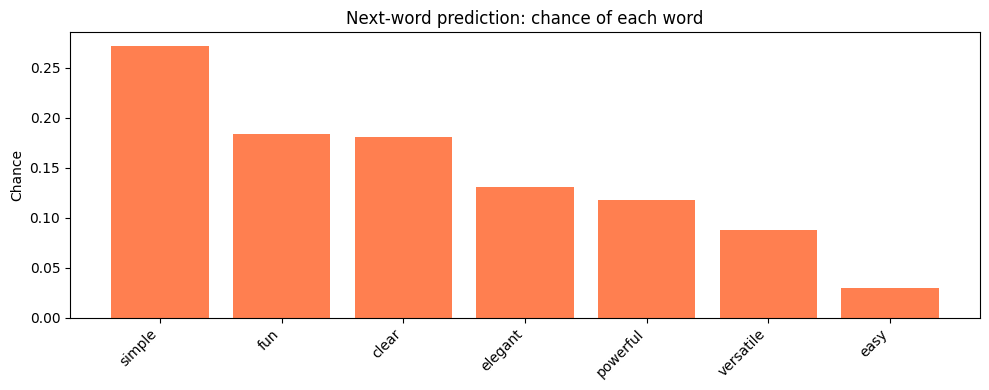


So what? Swap activities for words and you have ChatGPT.
Same counting, same guessing - just a far bigger pile of examples.


In [24]:
#@title ▶ Step 10 — Predict the next word, the way an LLM does { display-mode: "form" }
#@markdown Write the start of a sentence, and list the words it might end with.
sentence_so_far = "I love python because it is useless and " #@param {type:"string"}
possible_next_words = "fun, easy, powerful, versatile, simple, clear, elegant" #@param {type:"string"}

# ---- hidden helper code: learners never need to read this ----
import numpy as np, matplotlib.pyplot as plt
from collections import Counter
DEFAULTS = ["Sleep", "Work", "Exercise", "Social", "Leisure"]
NAMES = list(globals().get("_MY_ACTIVITIES") or DEFAULTS)
CUSTOM = bool(globals().get("_MY_ACTIVITIES"))
LOOK = {n.lower(): i for i, n in enumerate(NAMES)}
import sys
from IPython.display import display, HTML
def _msg(text, colour, weight):
    sys.stdout.flush()
    body = text.replace("&", "&amp;").replace("<", "&lt;").replace(">", "&gt;")
    display(HTML('<pre style="margin:0 0 2px 0;font-family:monospace;white-space:pre-wrap;'
                 'font-size:13px;color:' + colour + ';font-weight:' + weight + '">' + body + '</pre>'))
def problem(text): _msg(text, "#C8283C", "700")
def success(text): _msg(text, "#1a7f37", "700")
def note(text):    _msg(text, "#5f6368", "400")
def parse_days(text):
    out, bad = [], []
    for w in text.replace(chr(10), ",").split(","):
        w = w.strip()
        if not w: continue
        if w.lower() in LOOK: out.append(LOOK[w.lower()])
        elif w.isdigit() and 1 <= int(w) <= len(NAMES): out.append(int(w) - 1)
        else: bad.append(w)
    return out, bad
def say_bad(bad):
    if not bad: return
    import difflib
    problem("These are not among your five activities: " + ", ".join(bad))
    for w in bad[:3]:
        close = difflib.get_close_matches(w.lower(), [n.lower() for n in NAMES], n=1, cutoff=0.6)
        if close:
            note("   Did you mean " + NAMES[[n.lower() for n in NAMES].index(close[0])] + " instead of " + w + "?")
    note("Your five activities are: " + ", ".join(NAMES))
    note("Rewrite your days using those words, then press play again.")
    if not CUSTOM:
        note("(Tip: run Step 1 to choose your own activity names.)")
    print("")
SAMPLE = [0, 1, 2, 1, 3, 1, 4, 0, 1, 2, 1, 3, 1, 4, 0]
SAMPLE_LONG = SAMPLE + [1, 1, 2, 3, 4, 0]
def show_menu():
    note("Your five activities: " + ", ".join(str(i + 1) + "=" + n for i, n in enumerate(NAMES)))
    print("")
def show_days(days, heading):
    import textwrap
    words = ", ".join(NAMES[d] for d in days)
    nums = ", ".join(str(d + 1) for d in days)
    print(heading + "  (" + str(len(days)) + " days)")
    for line in textwrap.wrap(words, 70):
        print("   " + line)
    print("   as numbers:  " + nums)
    print("")
def get_days(use_sample, typed, sample=None, what="fortnight"):
    show_menu()
    typed = (typed or "").strip()
    if typed:
        if use_sample:
            note("You typed your own days, so I am using those instead of the sample.")
            print("")
        days, bad = parse_days(typed)
        say_bad(bad)
        if days: show_days(days, "Here is what I read from your box:")
        return days
    if use_sample:
        note("Using a sample " + what + " written in your activities.")
        note("Untick the box above and type your own days to make this about YOU.")
        print("")
        days = list(SAMPLE if sample is None else sample)
        show_days(days, "This is the sample data I am using:")
        return days
    problem("Nothing to work with yet.")
    note("Either tick the sample box above, or type some days, like: " + ", ".join(NAMES[:3]))
    return []
def busiest(days):
    return Counter(days).most_common(1)[0][0] if days else 0
def pick(word):
    w = word.strip().lower()
    if w in LOOK: return LOOK[w]
    if w.isdigit() and 1 <= int(w) <= len(NAMES): return int(w) - 1
    problem("I do not know the activity: " + word)
    note("Your five are: " + ", ".join(NAMES))
    return None

words = [w.strip() for w in possible_next_words.split(",") if w.strip()]
if len(words) < 2:
    problem("Please list at least 2 possible words, separated by commas.")
else:
    rng = np.random.RandomState(abs(hash(sentence_so_far)) % (2 ** 31))
    p = rng.rand(len(words)); p = p / p.sum()
    pairs = sorted(zip(words, p), key=lambda kv: -kv[1])
    print("Your sentence: \"" + sentence_so_far + " ___\"\n")
    print("The model's confidence in each ending:\n")
    for w, v in pairs:
        print("  " + w.ljust(12) + format(v, ">5.0%") + "  " + "#" * int(round(v * 40)))
    print("\nIt would most likely say: \"" + sentence_so_far + " " + pairs[0][0] + "\"")
    print("\nBut notice it does NOT always pick the top word. That small element of")
    print("chance is why the same question can get different answers twice -")
    print("and why models sometimes say something surprising.")
    plt.figure(figsize=(10, 4))
    plt.bar([w for w, _ in pairs], [v for _, v in pairs], color="coral")
    plt.title("Next-word prediction: chance of each word")
    plt.ylabel("Chance"); plt.xticks(rotation=45, ha="right")
    plt.tight_layout(); plt.show()
    print("")
    print("So what? Swap activities for words and you have ChatGPT.")
    print("Same counting, same guessing - just a far bigger pile of examples.")

### 🎯 Exercise 3.1 (Conceptual): Think it through

No code for this one — just thinking. Double-click the cell below to type your answers.

1. How is predicting the next **word** similar to predicting the next **activity**?
2. What job is probability doing in both cases?
3. Why might a language model sometimes produce an unexpected word?
4. How does context — the words before — lead to better predictions?

**Your answers** (double-click here to type):

1. Word prediction vs activity prediction:
   -

2. The role of probability:
   -

3. Why unexpected answers happen:
   -

4. Why context matters:
   -

---
## 🏆 Challenge: build a twin of your own week

The last step puts it all together. Describe a longer stretch of your life, and your twin
will learn your habits, predict your day, and show you the patterns it found.


This is the sample data I am using:  (21 days)
   Sleep, Brush, Eat, Brush, Wash, Brush, Leisure, Sleep, Brush, Eat,
   Brush, Wash, Brush, Leisure, Sleep, Brush, Brush, Eat, Wash, Leisure,
   Sleep
   as numbers:  1, 2, 3, 2, 4, 2, 5, 1, 2, 3, 2, 4, 2, 5, 1, 2, 2, 3, 4, 5, 1

                 YOUR DIGITAL TWIN                  

Built from 21 days of your life.

What it believes about you:
  Brush         38% of your days
  Sleep         19% of your days
  Eat           14% of your days
  Wash          14% of your days
  Leisure       14% of your days

Its most confident habit:
  After Leisure, you do Sleep (100% of the time)

Its least confident moment:
  After Brush, it is only 38% sure you will do Eat

Your next week, as predicted from BRUSH:
  Day 1: Eat
  Day 2: Brush
  Day 3: Eat
  Day 4: Brush
  Day 5: Eat
  Day 6: Brush
  Day 7: Eat


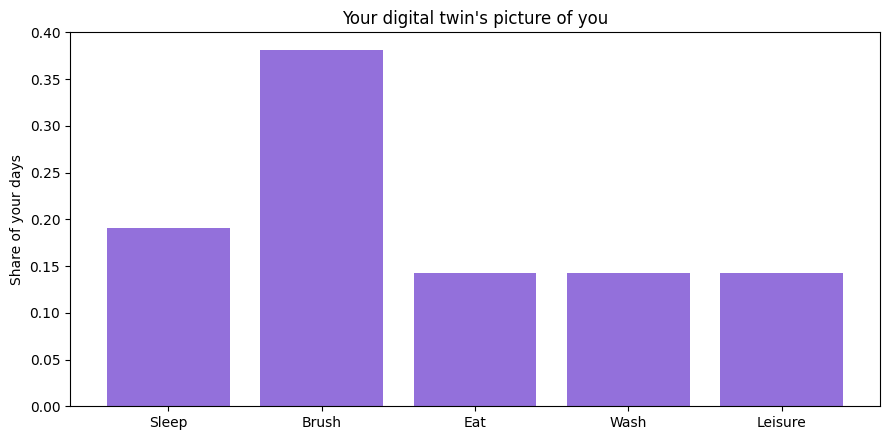


So what? This twin only knows what you told it. Feed it more days and it sharpens.
That is the whole lesson: AI is pattern-counting, carried out at speed.


In [25]:
#@title ▶ Step 11 — Build a digital twin of me { display-mode: "form" }
#@markdown The finale. Describe as many days as you can remember, in order.
#@markdown Leave it empty to use a sample stretch of days instead.
use_a_sample_week = True #@param {type:"boolean"}
my_life = "" #@param {type:"string"}
#@markdown Start the week-ahead prediction from which activity? (blank = your most common)
predict_from = "" #@param {type:"string"}

# ---- hidden helper code: learners never need to read this ----
import numpy as np, matplotlib.pyplot as plt
from collections import Counter
DEFAULTS = ["Sleep", "Work", "Exercise", "Social", "Leisure"]
NAMES = list(globals().get("_MY_ACTIVITIES") or DEFAULTS)
CUSTOM = bool(globals().get("_MY_ACTIVITIES"))
LOOK = {n.lower(): i for i, n in enumerate(NAMES)}
import sys
from IPython.display import display, HTML
def _msg(text, colour, weight):
    sys.stdout.flush()
    body = text.replace("&", "&amp;").replace("<", "&lt;").replace(">", "&gt;")
    display(HTML('<pre style="margin:0 0 2px 0;font-family:monospace;white-space:pre-wrap;'
                 'font-size:13px;color:' + colour + ';font-weight:' + weight + '">' + body + '</pre>'))
def problem(text): _msg(text, "#C8283C", "700")
def success(text): _msg(text, "#1a7f37", "700")
def note(text):    _msg(text, "#5f6368", "400")
def parse_days(text):
    out, bad = [], []
    for w in text.replace(chr(10), ",").split(","):
        w = w.strip()
        if not w: continue
        if w.lower() in LOOK: out.append(LOOK[w.lower()])
        elif w.isdigit() and 1 <= int(w) <= len(NAMES): out.append(int(w) - 1)
        else: bad.append(w)
    return out, bad
def say_bad(bad):
    if not bad: return
    import difflib
    problem("These are not among your five activities: " + ", ".join(bad))
    for w in bad[:3]:
        close = difflib.get_close_matches(w.lower(), [n.lower() for n in NAMES], n=1, cutoff=0.6)
        if close:
            note("   Did you mean " + NAMES[[n.lower() for n in NAMES].index(close[0])] + " instead of " + w + "?")
    note("Your five activities are: " + ", ".join(NAMES))
    note("Rewrite your days using those words, then press play again.")
    if not CUSTOM:
        note("(Tip: run Step 1 to choose your own activity names.)")
    print("")
SAMPLE = [0, 1, 2, 1, 3, 1, 4, 0, 1, 2, 1, 3, 1, 4, 0]
SAMPLE_LONG = SAMPLE + [1, 1, 2, 3, 4, 0]
def show_menu():
    note("Your five activities: " + ", ".join(str(i + 1) + "=" + n for i, n in enumerate(NAMES)))
    print("")
def show_days(days, heading):
    import textwrap
    words = ", ".join(NAMES[d] for d in days)
    nums = ", ".join(str(d + 1) for d in days)
    print(heading + "  (" + str(len(days)) + " days)")
    for line in textwrap.wrap(words, 70):
        print("   " + line)
    print("   as numbers:  " + nums)
    print("")
def get_days(use_sample, typed, sample=None, what="fortnight"):
    show_menu()
    typed = (typed or "").strip()
    if typed:
        if use_sample:
            note("You typed your own days, so I am using those instead of the sample.")
            print("")
        days, bad = parse_days(typed)
        say_bad(bad)
        if days: show_days(days, "Here is what I read from your box:")
        return days
    if use_sample:
        note("Using a sample " + what + " written in your activities.")
        note("Untick the box above and type your own days to make this about YOU.")
        print("")
        days = list(SAMPLE if sample is None else sample)
        show_days(days, "This is the sample data I am using:")
        return days
    problem("Nothing to work with yet.")
    note("Either tick the sample box above, or type some days, like: " + ", ".join(NAMES[:3]))
    return []
def busiest(days):
    return Counter(days).most_common(1)[0][0] if days else 0
def pick(word):
    w = word.strip().lower()
    if w in LOOK: return LOOK[w]
    if w.isdigit() and 1 <= int(w) <= len(NAMES): return int(w) - 1
    problem("I do not know the activity: " + word)
    note("Your five are: " + ", ".join(NAMES))
    return None

days = get_days(use_a_sample_week, my_life, sample=SAMPLE_LONG, what="stretch of days")
if len(days) < 5:
    if days: problem("I need at least 5 days to build a twin.")
else:
    counts = Counter(days); total = len(days)
    trans = {}
    for a, b in zip(days, days[1:]): trans.setdefault(a, []).append(b)
    print("=" * 52)
    print("YOUR DIGITAL TWIN".center(52))
    print("=" * 52)
    print("")
    print("Built from " + str(total) + " days of your life.")
    print("")
    print("What it believes about you:")
    for a, c in sorted(counts.items(), key=lambda kv: -kv[1]):
        print("  " + NAMES[a].ljust(12) + format(c / total, ">5.0%") + " of your days")
    conf = []
    for cur, nxts in trans.items():
        c = Counter(nxts); conf.append((max(c.values()) / len(nxts), cur, max(c, key=c.get)))
    conf.sort(reverse=True)
    sc, cur, nxt = conf[0]
    print("")
    print("Its most confident habit:")
    print("  After " + NAMES[cur] + ", you do " + NAMES[nxt] + " (" + format(sc, ".0%") + " of the time)")
    sc, cur, nxt = conf[-1]
    print("")
    print("Its least confident moment:")
    print("  After " + NAMES[cur] + ", it is only " + format(sc, ".0%") + " sure you will do " + NAMES[nxt])
    start = busiest(days) if not predict_from.strip() else pick(predict_from)
    if start is not None:
        print("")
        print("Your next week, as predicted from " + NAMES[start].upper() + ":")
        cur = start
        for i in range(1, 8):
            if cur not in trans:
                print("  Day " + str(i) + ": unknown"); break
            c = Counter(trans[cur]); nxt = max(c, key=c.get)
            print("  Day " + str(i) + ": " + NAMES[nxt]); cur = nxt
    plt.figure(figsize=(9, 4.5)); ks = sorted(counts)
    plt.bar([NAMES[k] for k in ks], [counts[k] / total for k in ks], color="mediumpurple")
    plt.title("Your digital twin's picture of you"); plt.ylabel("Share of your days")
    plt.tight_layout(); plt.show()
    print("")
    print("So what? This twin only knows what you told it. Feed it more days and it sharpens.")
    print("That is the whole lesson: AI is pattern-counting, carried out at speed.")

---
## Summary & Key Takeaways

1. **Probability** — AI predicts by counting what happened before.
2. **Conditional probability** — context matters; what came before changes what comes next.
3. **Neural networks** — learn the importance of each piece of evidence by themselves, through trial and error.
4. **Digital twin** — a model of someone's behaviour, built from their patterns.
5. **LLM connection** — language models do exactly this, with words instead of activities.

> You never wrote a line of code in this notebook. You still did the thinking that matters:
> choosing the data, reading the results, and judging whether the answers made sense.

### Next up
How models turn words into numbers (embeddings), the transformer, and attention.